# Example of the aitlas toolbox in the context of image segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import ChesapeakeDataset
from aitlas.models import DeepLabV3
from aitlas.utils import image_loader
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
import matplotlib.pyplot as plt
import csv

## Visualize images and masks

Total number of patches: 730


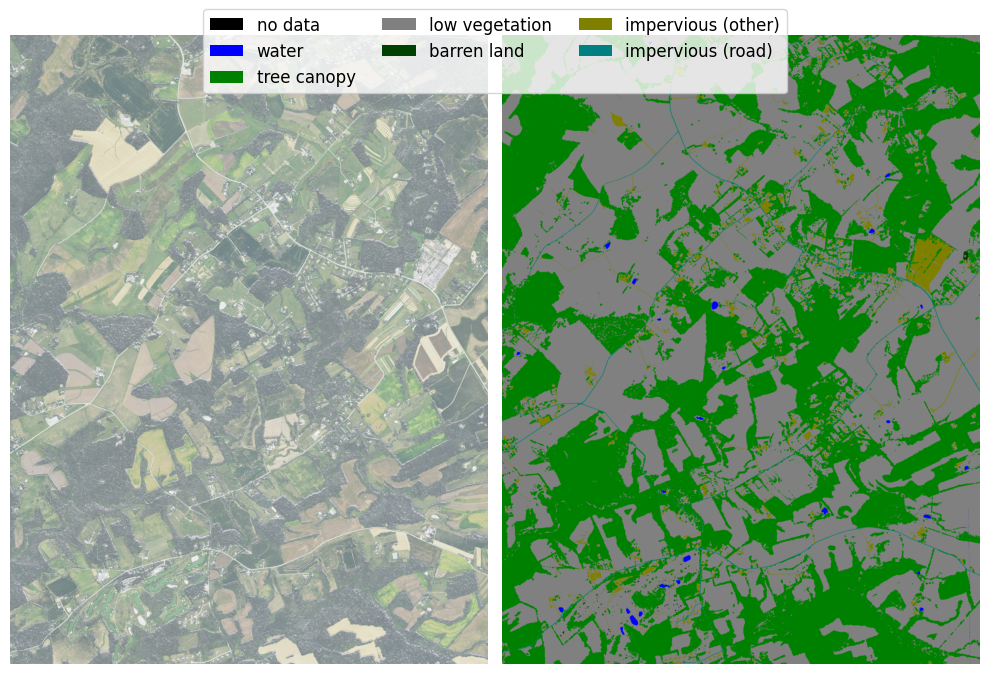

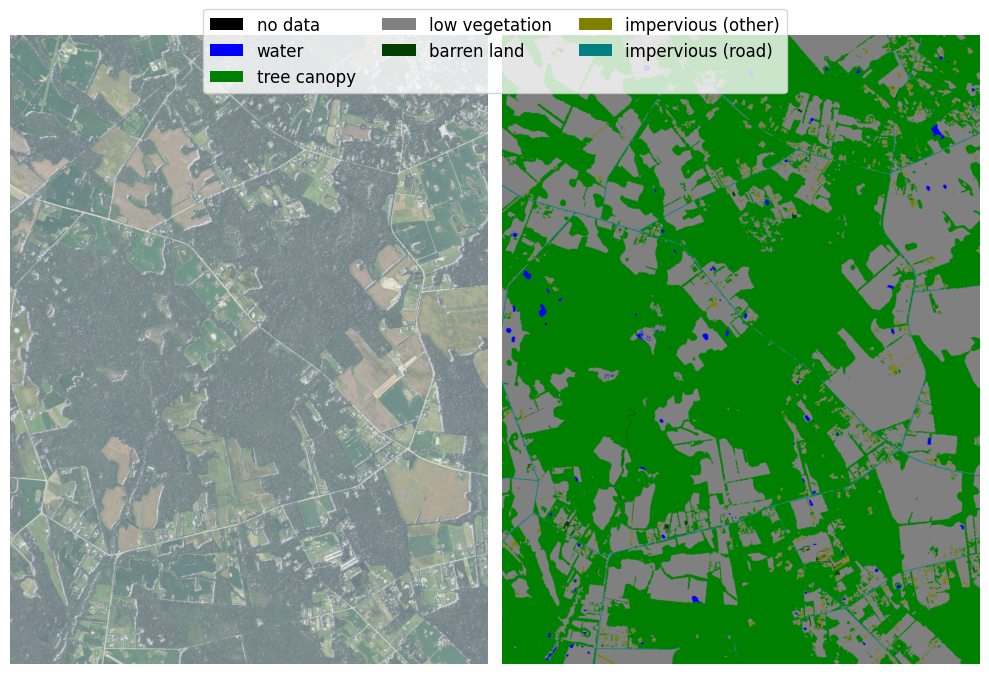

In [ ]:
dataset_config = {
    "data_dir": "./data/chesapeake",
    "selection": "all"
}
dataset = ChesapeakeDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(150);

In [10]:
dataset.data_distribution_table()

,Number of pixels
no data,0.000000e+00
water,9.616362e+08
tree canopy,1.364064e+10
low vegetation,7.283918e+09
barren land,6.608779e+07
impervious (other),5.831622e+08
impervious (road),3.030204e+08


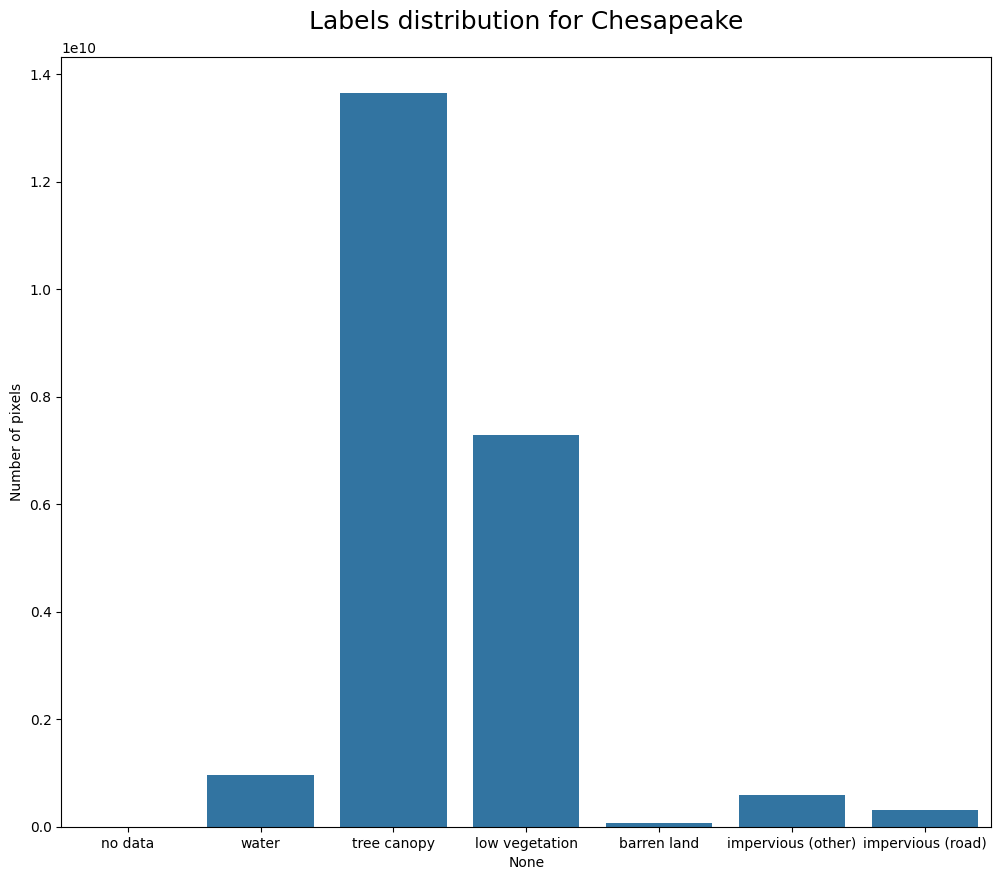

In [11]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/chesapeake",
    "csv_file": "./data/chesapeake/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = ChesapeakeDataset(train_dataset_config)
len(train_dataset)

584

## Create the model

In [ ]:
epochs = 5
model_directory = "./data/chesapeake"
model_config = {
    "num_classes": 7, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-05 09:19:50,515 INFO Starting training.
training: 100%|██████████| 146/146 [11:40:22<00:00, 287.82s/it]  
2025-05-05 21:00:12,781 INFO epoch: 1, time: 42022, loss:  0.62761
testing on train set: 100%|██████████| 146/146 [11:33:57<00:00, 285.19s/it]  
2025-05-06 08:34:12,265 INFO IOU:0.38120651182340143, IOU mean:0.13718565051053938, IOU per Class:[0.         0.13202641 0.55143245 0.27057489 0.         0.0062658
 0.        ]
training: 100%|██████████| 146/146 [11:33:35<00:00, 285.04s/it]  
2025-05-06 20:07:47,769 INFO epoch: 2, time: 41615, loss:  0.44765
testing on train set: 100%|██████████| 146/146 [11:31:09<00:00, 284.04s/it]  
2025-05-07 07:38:57,703 INFO IOU:0.4724880633657052, IOU mean:0.16023543600088144, IOU per Class:[0.         0.22020117 0.57106253 0.33038435 0.         0.
 0.        ]
training: 100%|██████████| 146/146 [11:37:06<00:00, 286.48s/it]  
2025-05-07 19:16:04,307 INFO epoch: 3, time: 41827, loss:  0.33230
testing on train set: 100%|██████████| 146/146 [11:

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/chesapeake",
    "csv_file": "./data/chesapeake/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = ChesapeakeDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/chesapeake/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

73


2025-05-12 06:44:36,291 INFO Loading checkpoint /home/dragik/data/FAIR_EO/chesapeake/checkpoint.pth.tar
2025-05-12 06:44:36,811 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/chesapeake/checkpoint.pth.tar at epoch 6
testing on test set: 100%|██████████| 19/19 [1:33:14<00:00, 294.45s/it]


[{'IOU': 0.554559983577355,
  'IOU mean': 0.2386719279358827,
  'IOU per Class': array([0.        , 0.6316773 , 0.63306836, 0.40595784, 0.        ,
         0.        , 0.        ])}]

## Predictions

2025-05-12 08:21:06,599 INFO Loading checkpoint /home/dragik/data/FAIR_EO/chesapeake/checkpoint.pth.tar
2025-05-12 08:21:06,999 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/chesapeake/checkpoint.pth.tar at epoch 6


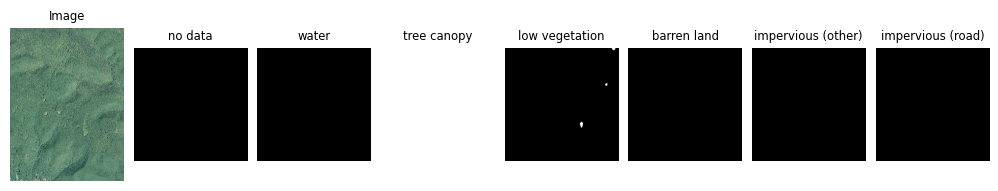

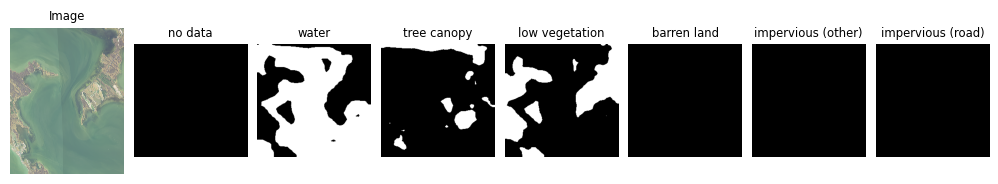

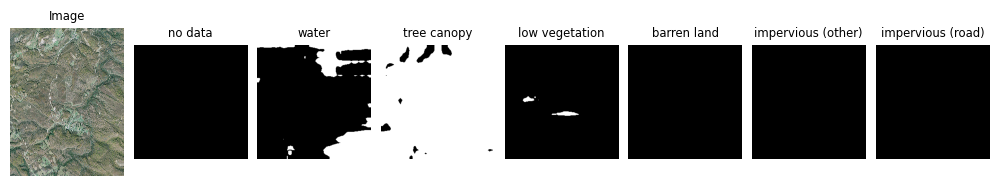

In [ ]:
model_path = "./data/chesapeake/checkpoint.pth.tar"
labels = ["no data","water","tree canopy","low vegetation","barren land","impervious (other)","impervious (road)"]
transform = ResizeToTensor()
model.load_model(model_path)
plt.rcParams.update({'font.size': 7})
csv_file = "./data/chesapeake/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/chesapeake/' + test_list[0])
image = image[:,:,0:3]
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/chesapeake/' + test_list[1])
image = image[:,:,0:3]
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/chesapeake/' + test_list[10])
image = image[:,:,0:3]
fig = model.predict_masks(image, labels, transform)